# Notebook 02 — Approach 1: Classical CV + ML

HSV/LAB color histograms + LBP texture → SVM and Random Forest

In [1]:
import os, sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from src.dataset import load_images_from_folder, get_train_val_split, CLASS_NAMES
from src.classical_model import (extract_features_batch, build_svm,
                                  build_random_forest, save_model)

DATA_DIR = '../data/raw'


## 1. Load & Split Data

In [2]:
print("Loading training images...")
X_train_full, X_val, y_train_full, y_val = get_train_val_split(
    os.path.join(DATA_DIR, 'train'), val_size=0.15
)
X_test, y_test = load_images_from_folder(os.path.join(DATA_DIR, 'test'))
print(f"Train: {len(X_train_full)} | Val: {len(X_val)} | Test: {len(X_test)}")


Loading training images...
Train: 842 | Val: 149 | Test: 99


## 2. Feature Extraction

In [3]:
print("Extracting features (train)...")
F_train = extract_features_batch(X_train_full)
print("Extracting features (val)...")
F_val   = extract_features_batch(X_val)
print("Extracting features (test)...")
F_test  = extract_features_batch(X_test)
print(f"Feature vector size: {F_train.shape[1]}")


Extracting features (train)...
Extracting features (val)...
Extracting features (test)...
Feature vector size: 107


## 3. Train SVM

In [4]:
svm = build_svm()
print("Training SVM...")
svm.fit(F_train, y_train_full)

val_preds_svm = svm.predict(F_val)
print(f"SVM Val Accuracy: {accuracy_score(y_val, val_preds_svm):.4f}")
print(f"SVM Val F1 (macro): {f1_score(y_val, val_preds_svm, average='macro'):.4f}")


Training SVM...
SVM Val Accuracy: 1.0000
SVM Val F1 (macro): 1.0000


## 4. Train Random Forest

In [5]:
rf = build_random_forest()
print("Training Random Forest...")
rf.fit(F_train, y_train_full)

val_preds_rf = rf.predict(F_val)
print(f"RF Val Accuracy : {accuracy_score(y_val, val_preds_rf):.4f}")
print(f"RF Val F1 (macro): {f1_score(y_val, val_preds_rf, average='macro'):.4f}")


Training Random Forest...
RF Val Accuracy : 0.9933
RF Val F1 (macro): 0.9909


## 5. Test Set Evaluation

In [6]:
test_preds_svm = svm.predict(F_test)
test_preds_rf  = rf.predict(F_test)

print("=== SVM Test Results ===")
print(classification_report(y_test, test_preds_svm, target_names=CLASS_NAMES))

print("=== Random Forest Test Results ===")
print(classification_report(y_test, test_preds_rf, target_names=CLASS_NAMES))


=== SVM Test Results ===
              precision    recall  f1-score   support

   blackspot       0.95      0.95      0.95        22
      canker       0.95      0.95      0.95        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.98        99
   macro avg       0.98      0.98      0.98        99
weighted avg       0.98      0.98      0.98        99

=== Random Forest Test Results ===
              precision    recall  f1-score   support

   blackspot       0.91      0.95      0.93        22
      canker       0.95      0.91      0.93        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



## 6. Confusion Matrices

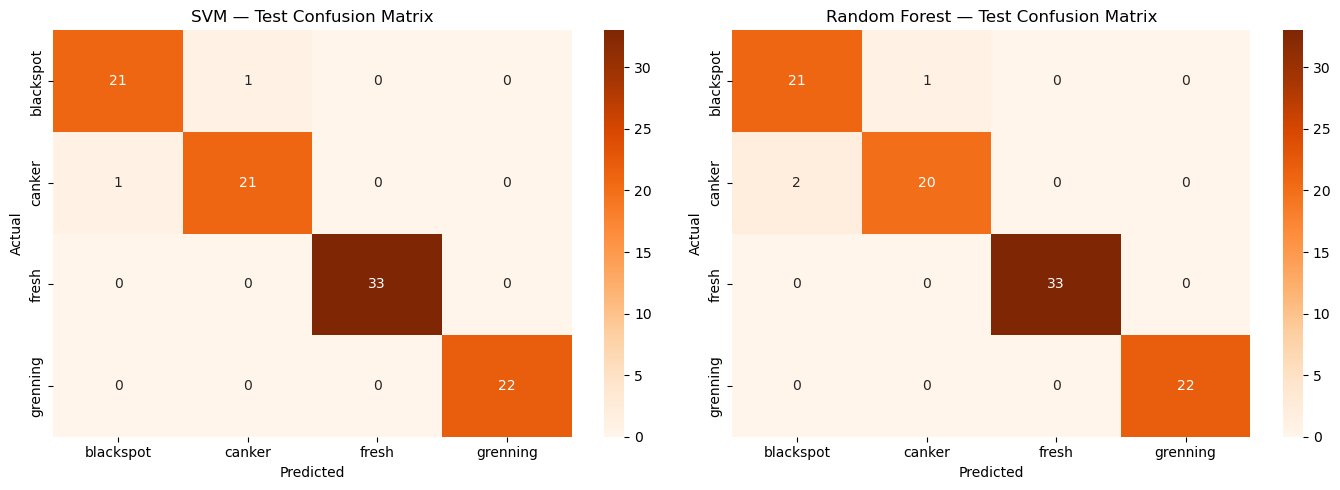

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, title in [
    (axes[0], test_preds_svm, 'SVM'),
    (axes[1], test_preds_rf,  'Random Forest')
]:
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'{title} — Test Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('../report/classical_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Save Models

In [9]:
import os
os.makedirs('../models', exist_ok=True)
save_model(svm, '../models/svm_model.joblib')
save_model(rf,  '../models/rf_model.joblib')
print("Models saved to ../models/")


Models saved to ../models/
